In [1]:
import xarray as xr
import os
import socket
import numpy as np
import matplotlib.pyplot as plt
import subprocess

host = socket.gethostname()
if host == 'mpc2959.psi.ch' or host == 'mpc2053.psi.ch':
    gitpath = '/mpc/homes/fische_r/lib/co2ely-tomcat'
    toppath = '/mpc/homes/fische_r/NAS/DASCOELY'
    toppathSSD = '/mnt/SSD/fische_r/COELY'
    temppath = '/mnt/SSD/fische_r/tmp'
    training_path = '/mpc/homes/fische_r/NAS/DASCOELY/processing/05_water_GDL_ML/'
    
else:
    print('currently '+host+'not supported')
    
path_02_4D = os.path.join(toppathSSD, '02_registered_3p1D') #h5 with registered data
if not host=='mpc2959.psi.ch':
    path_02_4D = os.path.join(toppath, 'processing','02_registered_3p1D') #h5 with registered data

# fetch githash
cwd = os.getcwd()
os.chdir(gitpath)
git_sha = subprocess.check_output(['git', 'rev-parse', '--short', 'HEAD']).decode().strip()
githash = subprocess.check_output(['git', 'rev-parse', 'HEAD']).decode().strip()
os.chdir(cwd)

In [3]:
sample = '3II'
segpath = os.path.join(toppath, 'processing','06_anode_CL', ''.join(['06_'+sample,'_anode_CL_segmented.nc']))

seg_data = xr.open_dataset(segpath)

In [ ]:
def calculate_anode_CL_area(sample, toppath=toppath):
    segpath = os.path.join(toppath, 'processing','06_anode_CL', ''.join(['06_'+sample,'_anode_CL_segmented.nc']))
    seg_data = xr.open_dataset(segpath)
    CLareas = (seg_data['segmented'].sum(dim='y')>0).sum(dim = ('x','z')).data
    seg_data.close()
    return CLareas

In [46]:
seg_data.close()

In [32]:
CLareas = (seg_data['segmented'].sum(dim='y')>0).sum(dim = ('x','z'))

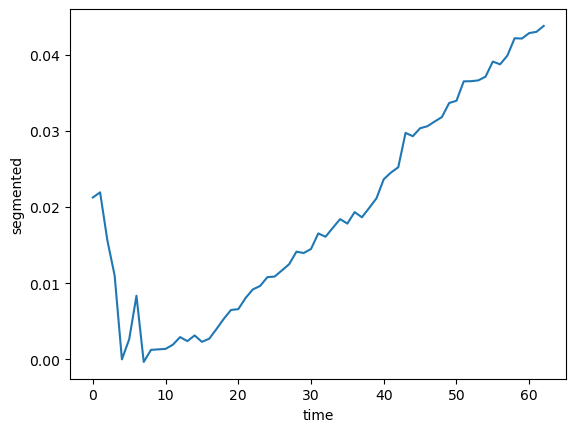

In [45]:
((CLareas[4]-CLareas)/CLareas[4]).plot()

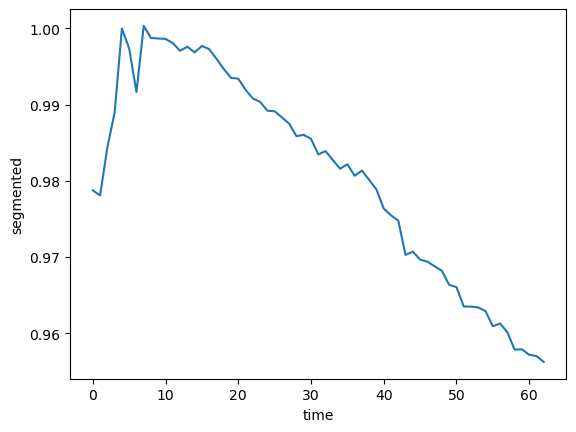

In [44]:
(CLareas/CLareas[4]).plot()

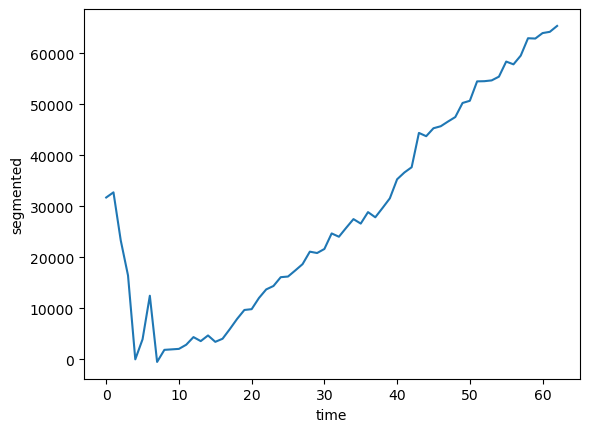

In [43]:
(CLareas[4]-CLareas).plot()